checking the hardware accelerator


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / 1e9, 2
    ))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64


installing the required libraries

In [2]:
%pip install -q transformers peft datasets accelerate scikit-learn

importing the required libraries


In [3]:
import torch
import transformers
import peft
import datasets
import accelerate
import sklearn

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Transformers: 5.20.2
PEFT: 0.21.2
Datasets: 4.8.5
Accelerate: 1.15.0
Scikit-learn: 1.6.1
GPU: Tesla T4


In [17]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


hugging face authorization


In [5]:
from huggingface_hub import login
login()

model accessing

In [7]:
from huggingface_hub import HfApi

model_id = "meta-llama/Llama-3.2-1B"

info = HfApi().model_info(model_id)

print("Model access confirmed.")
print("Model:", info.id)

Model access confirmed.
Model: meta-llama/Llama-3.2-1B


load the model and tokenizer

In [8]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "meta-llama/Llama-3.2-1B"

print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Loading sequence-classification model...")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    torch_dtype=torch.float16,
)

model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False

print("\nModel loaded successfully!")
print("Model:", MODEL_NAME)
print("Parameters (billions):", round(
    sum(p.numel() for p in model.parameters()) / 1e9, 3
))
print("GPU memory allocated (GB):", round(
    torch.cuda.memory_allocated() / 1e9, 2
))

Loading tokenizer...


config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

Loading sequence-classification model...


... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Model loaded successfully!
Model: meta-llama/Llama-3.2-1B
Parameters (billions): 1.236
GPU memory allocated (GB): 0.0


check model placement and memory

In [10]:
import torch

print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    torch.cuda.synchronize()
    print(
        "GPU memory allocated (GB):",
        round(torch.cuda.memory_allocated(0) / 1e9, 2)
    )
    print(
        "GPU memory reserved (GB):",
        round(torch.cuda.memory_reserved(0) / 1e9, 2)
    )

print("Has device map:", hasattr(model, "hf_device_map"))
if hasattr(model, "hf_device_map"):
    print("Device map:", model.hf_device_map)

Model device: cpu
Model dtype: torch.float16
CUDA available: True
GPU memory allocated (GB): 0.0
GPU memory reserved (GB): 0.0
Has device map: False


move the model to the GPU

In [11]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Check the Colab GPU runtime.")

model = model.to("cuda")

torch.cuda.synchronize()

print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory allocated (GB):",
    round(torch.cuda.memory_allocated(0) / 1e9, 2)
)

Model device: cuda:0
Model dtype: torch.float16
GPU: Tesla T4
GPU memory allocated (GB): 2.47


test a forward pass

In [12]:
import torch

premise = "A person is riding a bicycle on the road."
hypothesis = "Someone is riding a vehicle."

inputs = tokenizer(
    premise,
    hypothesis,
    return_tensors="pt",
    truncation=True,
    max_length=256,
)

# Send the input tensors to the same device as the model.
inputs = {key: value.to(next(model.parameters()).device)
          for key, value in inputs.items()}

model.eval()

with torch.no_grad():
    outputs = model(**inputs)

print("Forward pass successful!")
print("Logits shape:", tuple(outputs.logits.shape))
print("Number of classes:", outputs.logits.shape[-1])
print("GPU memory allocated (GB):",
      round(torch.cuda.memory_allocated(0) / 1e9, 2))

Forward pass successful!
Logits shape: (1, 3)
Number of classes: 3
GPU memory allocated (GB): 2.48


load the model to attach

In [1]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "meta-llama/Llama-3.2-1B"

print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU unavailable. Check Runtime > Change runtime type.")

print("GPU:", torch.cuda.get_device_name(0))

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Loading model...")
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    dtype=torch.float16,
)

model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False

model = model.to("cuda")

print("\nModel loaded successfully!")
print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)
print(
    "GPU memory allocated (GB):",
    round(torch.cuda.memory_allocated(0) / 1e9, 2)
)

CUDA available: True
GPU: Tesla T4
Loading tokenizer...
Loading model...


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Model loaded successfully!
Model device: cuda:0
Model dtype: torch.float16
GPU memory allocated (GB): 2.47


attaching lora

In [2]:
from peft import LoraConfig, TaskType, get_peft_model

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    lora_dropout=0.1,
    bias="none",
)

model = get_peft_model(model, lora_config)

if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()

model.print_trainable_parameters()

trainable params: 3,414,016 || all params: 1,239,234,560 || trainable%: 0.2755


check the trainable parameters names

In [3]:
trainable_names = [
    name
    for name, parameter in model.named_parameters()
    if parameter.requires_grad
]

print("First 20 trainable parameter names:")
for name in trainable_names[:20]:
    print(name)

print("\nTotal trainable tensors:", len(trainable_names))

print(
    "\nTrainable classification-head parameters:",
    sum(
        parameter.numel()
        for name, parameter in model.named_parameters()
        if parameter.requires_grad and "score" in name
    )
)

First 20 trainable parameter names:
base_model.model.model.layers.0.self_attn.q_proj.lora_A.default.weight
base_model.model.model.layers.0.self_attn.q_proj.lora_B.default.weight
base_model.model.model.layers.0.self_attn.k_proj.lora_A.default.weight
base_model.model.model.layers.0.self_attn.k_proj.lora_B.default.weight
base_model.model.model.layers.0.self_attn.v_proj.lora_A.default.weight
base_model.model.model.layers.0.self_attn.v_proj.lora_B.default.weight
base_model.model.model.layers.0.self_attn.o_proj.lora_A.default.weight
base_model.model.model.layers.0.self_attn.o_proj.lora_B.default.weight
base_model.model.model.layers.1.self_attn.q_proj.lora_A.default.weight
base_model.model.model.layers.1.self_attn.q_proj.lora_B.default.weight
base_model.model.model.layers.1.self_attn.k_proj.lora_A.default.weight
base_model.model.model.layers.1.self_attn.k_proj.lora_B.default.weight
base_model.model.model.layers.1.self_attn.v_proj.lora_A.default.weight
base_model.model.model.layers.1.self_attn

load and inspect the XNLI dataset

In [4]:
from datasets import load_dataset

print("Loading English XNLI training split...")

xnli_train_en = load_dataset(
    "facebook/xnli",
    "en",
    split="train",
)

print("\nDataset loaded successfully.")
print("Number of training examples:", len(xnli_train_en))
print("Columns:", xnli_train_en.column_names)
print("First example:", xnli_train_en[0])

Loading English XNLI training split...


README.md:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

en/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 50.2MB            

en/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

en/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/392702 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5010 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2490 [00:00<?, ? examples/s]


Dataset loaded successfully.
Number of training examples: 392702
Columns: ['premise', 'hypothesis', 'label']
First example: {'premise': 'Conceptually cream skimming has two basic dimensions - product and geography .', 'hypothesis': 'Product and geography are what make cream skimming work .', 'label': 1}


load and sample the three languages

In [5]:
from datasets import load_dataset

LANGUAGES = ["en", "hi", "de"]

for language in LANGUAGES:
    print(f"\nChecking language: {language}")

    train_dataset = load_dataset(
        "facebook/xnli",
        language,
        split="train",
    )

    test_dataset = load_dataset(
        "facebook/xnli",
        language,
        split="test",
    )

    print("Training examples available:", len(train_dataset))
    print("Test examples available:", len(test_dataset))
    print("Columns:", train_dataset.column_names)
    print("First training example:", train_dataset[0])


Checking language: en
Training examples available: 392702
Test examples available: 5010
Columns: ['premise', 'hypothesis', 'label']
First training example: {'premise': 'Conceptually cream skimming has two basic dimensions - product and geography .', 'hypothesis': 'Product and geography are what make cream skimming work .', 'label': 1}

Checking language: hi


hi/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 70.2MB            

hi/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

hi/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  493kB            

hi/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

hi/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  249kB            

... (11 outputs left out)

Generating train split:   0%|          | 0/392702 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5010 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2490 [00:00<?, ? examples/s]

Training examples available: 392702
Test examples available: 5010
Columns: ['premise', 'hypothesis', 'label']
First training example: {'premise': 'Konzeptionell cream abschöpfen hat zwei grundlegende Dimensionen - Produkt und Geographie .', 'hypothesis': 'Produkt und Geographie sind das , was creme abschöpfen Arbeit macht .', 'label': 1}


create reproducible training and test subsets

In [6]:
from datasets import load_dataset

LANGUAGES = ["en", "hi", "de"]

TRAIN_SAMPLES = 5000
TEST_SAMPLES = 1000

TRAIN_SEED = 42
TEST_SEED = 123

train_datasets = {}
test_datasets = {}

for language in LANGUAGES:
    print(f"\nPreparing {language}...")

    full_train = load_dataset(
        "facebook/xnli",
        language,
        split="train",
    )

    full_test = load_dataset(
        "facebook/xnli",
        language,
        split="test",
    )

    # Select reproducible subsets independently from each full split.
    train_datasets[language] = (
        full_train
        .shuffle(seed=TRAIN_SEED)
        .select(range(TRAIN_SAMPLES))
    )

    test_datasets[language] = (
        full_test
        .shuffle(seed=TEST_SEED)
        .select(range(TEST_SAMPLES))
    )

    print("Training subset:", len(train_datasets[language]))
    print("Test subset:", len(test_datasets[language]))

print("\nAll language subsets prepared.")


Preparing en...
Training subset: 5000
Test subset: 1000

Preparing hi...
Training subset: 5000
Test subset: 1000

Preparing de...
Training subset: 5000
Test subset: 1000

All language subsets prepared.


verify the labels and dataset structure

In [7]:
from collections import Counter

EXPECTED_COLUMNS = {"premise", "hypothesis", "label"}
VALID_LABELS = {0, 1, 2}

for language in LANGUAGES:
    print(f"\n--- {language.upper()} ---")

    train_ds = train_datasets[language]
    test_ds = test_datasets[language]

    # Check the required columns.
    assert EXPECTED_COLUMNS.issubset(train_ds.column_names)
    assert EXPECTED_COLUMNS.issubset(test_ds.column_names)

    # Check that every label is valid.
    train_labels = Counter(train_ds["label"])
    test_labels = Counter(test_ds["label"])

    assert set(train_labels).issubset(VALID_LABELS)
    assert set(test_labels).issubset(VALID_LABELS)

    # Check for empty premise or hypothesis text.
    assert all(text.strip() for text in train_ds["premise"])
    assert all(text.strip() for text in train_ds["hypothesis"])
    assert all(text.strip() for text in test_ds["premise"])
    assert all(text.strip() for text in test_ds["hypothesis"])

    print("Training examples:", len(train_ds))
    print("Training label counts:", dict(sorted(train_labels.items())))
    print("Test examples:", len(test_ds))
    print("Test label counts:", dict(sorted(test_labels.items())))
    print("Dataset checks passed.")

print("\nAll dataset checks passed.")


--- EN ---
Training examples: 5000
Training label counts: {0: 1650, 1: 1732, 2: 1618}
Test examples: 1000
Test label counts: {0: 323, 1: 341, 2: 336}
Dataset checks passed.

--- HI ---
Training examples: 5000
Training label counts: {0: 1650, 1: 1732, 2: 1618}
Test examples: 1000
Test label counts: {0: 323, 1: 341, 2: 336}
Dataset checks passed.

--- DE ---
Training examples: 5000
Training label counts: {0: 1650, 1: 1732, 2: 1618}
Test examples: 1000
Test label counts: {0: 323, 1: 341, 2: 336}
Dataset checks passed.

All dataset checks passed.


preparing small lora training step test

In [8]:
import torch
from transformers import DataCollatorWithPadding
from torch.utils.data import DataLoader

# Use 8 English examples for the technical test.
smoke_dataset = train_datasets["en"].select(range(8))

def tokenize_example(example):
    encoded = tokenizer(
        example["premise"],
        example["hypothesis"],
        truncation=True,
        max_length=256,
    )
    encoded["labels"] = int(example["label"])
    return encoded

smoke_tokenized = smoke_dataset.map(
    tokenize_example,
    remove_columns=smoke_dataset.column_names,
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8,
)

smoke_loader = DataLoader(
    smoke_tokenized,
    batch_size=4,
    shuffle=False,
    collate_fn=collator,
)

# Confirm that the model is in training mode.
model.train()

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=2e-4,
)

batch = next(iter(smoke_loader))
batch = {
    key: value.to("cuda")
    for key, value in batch.items()
}

optimizer.zero_grad(set_to_none=True)

outputs = model(**batch)
loss = outputs.loss

print("Loss before backward:", loss.item())

loss.backward()

# Verify that trainable parameters received gradients.
grad_params = sum(
    1 for p in model.parameters()
    if p.requires_grad and p.grad is not None
)

print("Trainable tensors with gradients:", grad_params)

optimizer.step()

print("Optimizer step completed.")
print("GPU memory allocated (GB):",
      round(torch.cuda.memory_allocated(0) / 1e9, 2))

Map:   0%|          | 0/8 [00:00<?, ? examples/s]

Loss before backward: 0.16748046875
Trainable tensors with gradients: 129
Optimizer step completed.
GPU memory allocated (GB): 2.55


reload the fresh model

In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import LoraConfig, TaskType, get_peft_model

MODEL_NAME = "meta-llama/Llama-3.2-1B"

# Reload the tokenizer.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Reload the original pretrained model.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    dtype=torch.float16,
)

model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False
model = model.to("cuda")

# Attach a fresh LoRA adapter.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    lora_dropout=0.1,
    bias="none",
)

model = get_peft_model(model, lora_config)

if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()

model.print_trainable_parameters()

print("Device:", next(model.parameters()).device)
print("GPU memory allocated (GB):",
      round(torch.cuda.memory_allocated(0) / 1e9, 2))

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 3,414,016 || all params: 1,239,234,560 || trainable%: 0.2755
Device: cuda:0
GPU memory allocated (GB): 2.56


check that the fresh model can evaluate examples

In [10]:
import torch

model.eval()

for language in ["en", "hi", "de"]:
    example = test_datasets[language][0]

    inputs = tokenizer(
        example["premise"],
        example["hypothesis"],
        return_tensors="pt",
        truncation=True,
        max_length=256,
    )

    inputs = {
        key: value.to("cuda")
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    predicted_label = outputs.logits.argmax(dim=-1).item()

    print(
        f"Language: {language} | "
        f"Predicted label: {predicted_label} | "
        f"Logits shape: {tuple(outputs.logits.shape)}"
    )

Language: en | Predicted label: 2 | Logits shape: (1, 3)
Language: hi | Predicted label: 2 | Logits shape: (1, 3)
Language: de | Predicted label: 1 | Logits shape: (1, 3)


preparing the baseline experiment

In [11]:
import random
import numpy as np
import torch

SEED = 42
LANGUAGES = ["en", "hi", "de"]

TRAIN_SAMPLES = 5000
TEST_SAMPLES = 1000

BATCH_SIZE = 4
MAX_LENGTH = 256
LEARNING_RATE = 2e-4
NUM_EPOCHS = 1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Experiment settings")
print("Language order:", " -> ".join(LANGUAGES))
print("Training examples per language:", TRAIN_SAMPLES)
print("Test examples per language:", TEST_SAMPLES)
print("Batch size:", BATCH_SIZE)
print("Maximum sequence length:", MAX_LENGTH)
print("Learning rate:", LEARNING_RATE)
print("Epochs per language:", NUM_EPOCHS)
print("Replay: Disabled")
print("GPU:", torch.cuda.get_device_name(0))

Experiment settings
Language order: en -> hi -> de
Training examples per language: 5000
Test examples per language: 1000
Batch size: 4
Maximum sequence length: 256
Learning rate: 0.0002
Epochs per language: 1
Replay: Disabled
GPU: Tesla T4


evaluate the untrained model on all three languages

In [12]:
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

model.eval()

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8,
)

initial_results = {}

for language in LANGUAGES:
    dataset = test_datasets[language]

    def tokenize_batch(batch):
        return tokenizer(
            batch["premise"],
            batch["hypothesis"],
            truncation=True,
            max_length=MAX_LENGTH,
        )

    tokenized = dataset.map(
        tokenize_batch,
        batched=True,
        remove_columns=[
            column for column in dataset.column_names
            if column not in ["label"]
        ],
    )

    tokenized = tokenized.rename_column("label", "labels")

    loader = DataLoader(
        tokenized,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collator,
    )

    all_predictions = []
    all_labels = []

    for batch in loader:
        batch = {
            key: value.to("cuda")
            for key, value in batch.items()
        }

        with torch.no_grad():
            outputs = model(**batch)

        predictions = outputs.logits.argmax(dim=-1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(batch["labels"].cpu().tolist())

    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0,
    )

    initial_results[language] = {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
    }

    print(
        f"{language.upper()} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Macro-F1: {macro_f1:.4f}"
    )

print("\nInitial evaluation completed. No training was performed.")

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

EN | Accuracy: 0.3420 | Macro-F1: 0.2106


Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

HI | Accuracy: 0.3470 | Macro-F1: 0.2569


Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

DE | Accuracy: 0.3630 | Macro-F1: 0.3543

Initial evaluation completed. No training was performed.


train on english

In [13]:
from transformers import (
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
)
import torch

# Tokenize the English training data.
def tokenize_for_training(batch):
    encoded = tokenizer(
        batch["premise"],
        batch["hypothesis"],
        truncation=True,
        max_length=MAX_LENGTH,
    )
    encoded["labels"] = batch["label"]
    return encoded

english_train_tokenized = train_datasets["en"].map(
    tokenize_for_training,
    batched=True,
    remove_columns=train_datasets["en"].column_names,
)

# Dynamic padding makes each batch only as long as needed.
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8,
)

# Use a separate directory for this experiment's first checkpoint.
OUTPUT_DIR = "/content/xnli_lora_baseline"

training_args = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/stage_en",
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy="epoch",
    fp16=True,
    gradient_checkpointing=True,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
    optim="adamw_torch",
)

print("English training examples:", len(english_train_tokenized))
print("Trainer configuration prepared.")
print("Training has NOT started yet.")

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

English training examples: 5000
Trainer configuration prepared.
Training has NOT started yet.


In [15]:
# Disable Trainer-managed FP16 gradient scaling.
training_args = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/stage_en",
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy="epoch",
    fp16=False,
    bf16=False,
    gradient_checkpointing=True,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
    optim="adamw_torch",
)

print("FP16 Trainer mode:", training_args.fp16)
print("BF16 Trainer mode:", training_args.bf16)
print("Model parameter dtype:", next(model.parameters()).dtype)
print("Model device:", next(model.parameters()).device)

FP16 Trainer mode: False
BF16 Trainer mode: False
Model parameter dtype: torch.float16
Model device: cuda:0


In [16]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import LoraConfig, TaskType, get_peft_model

MODEL_NAME = "meta-llama/Llama-3.2-1B"

# Load tokenizer.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load model in FP32 (the default dtype).
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    dtype=torch.float32,
)

model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False
model = model.to("cuda")

# Attach a fresh LoRA adapter.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    lora_dropout=0.1,
    bias="none",
)

model = get_peft_model(model, lora_config)

if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()

model.print_trainable_parameters()

print("Model parameter dtype:", next(model.parameters()).dtype)
print("Model device:", next(model.parameters()).device)
print("GPU memory allocated (GB):",
      round(torch.cuda.memory_allocated(0) / 1e9, 2))

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: meta-llama/Llama-3.2-1B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 3,414,016 || all params: 1,239,234,560 || trainable%: 0.2755
Model parameter dtype: torch.float32
Model device: cuda:0
GPU memory allocated (GB): 7.53


In [17]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/stage_en",
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy="epoch",
    fp16=True,
    bf16=False,
    gradient_checkpointing=True,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
    optim="adamw_torch",
)

print("Trainer FP16 enabled:", training_args.fp16)
print("Model parameter dtype:", next(model.parameters()).dtype)
print("GPU:", torch.cuda.get_device_name(0))

Trainer FP16 enabled: True
Model parameter dtype: torch.float32
GPU: Tesla T4


In [21]:
# Create a fresh Trainer using the reloaded model.
trainer_en = Trainer(
    model=model,
    args=training_args,
    train_dataset=english_train_tokenized,
    data_collator=data_collator,
)

print("Trainable parameters:")
model.print_trainable_parameters()

print("Starting English training...")
train_result_en = trainer_en.train()

print("\nEnglish training completed.")
print("Training metrics:", train_result_en.metrics)

Trainable parameters:
trainable params: 3,414,016 || all params: 1,239,234,560 || trainable%: 0.2755
Starting English training...


Step,Training Loss
100,0.800100
200,1.173923
300,0.861639
400,0.735516
500,0.803641
600,0.715589
700,0.771239
800,0.702256
900,0.692659
1000,0.668608



English training completed.
Training metrics: {'train_runtime': 290.7224, 'train_samples_per_second': 17.199, 'train_steps_per_second': 4.3, 'total_flos': 1864694702407680.0, 'train_loss': 0.7516661727905274, 'epoch': 1.0}


evaluate all three languages after english training

In [22]:
import torch
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader

def evaluate_language(model, dataset, language):
    model.eval()

    def tokenize_batch(batch):
        return tokenizer(
            batch["premise"],
            batch["hypothesis"],
            truncation=True,
            max_length=MAX_LENGTH,
        )

    tokenized = dataset.map(
        tokenize_batch,
        batched=True,
        remove_columns=[
            column for column in dataset.column_names
            if column != "label"
        ],
    )

    tokenized = tokenized.rename_column("label", "labels")

    loader = DataLoader(
        tokenized,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=data_collator,
    )

    predictions = []
    labels = []

    for batch in loader:
        batch = {
            key: value.to("cuda")
            for key, value in batch.items()
        }

        with torch.no_grad():
            outputs = model(**batch)

        predictions.extend(
            outputs.logits.argmax(dim=-1).cpu().tolist()
        )
        labels.extend(batch["labels"].cpu().tolist())

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        ),
    }

after_english_results = {}

for language in LANGUAGES:
    metrics = evaluate_language(
        model,
        test_datasets[language],
        language,
    )
    after_english_results[language] = metrics

    print(
        f"{language.upper()} | "
        f"Accuracy: {metrics['accuracy']:.4f} | "
        f"Macro-F1: {metrics['macro_f1']:.4f}"
    )

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

EN | Accuracy: 0.8300 | Macro-F1: 0.8319


Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

HI | Accuracy: 0.4570 | Macro-F1: 0.4094


Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

DE | Accuracy: 0.5960 | Macro-F1: 0.5292


saving the results after english training

In [23]:
import json
import os

RESULTS_DIR = "/content/xnli_lora_baseline/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

results_so_far = {
    "experiment": "Phase 1 B0 - Sequential XNLI baseline",
    "language_order": LANGUAGES,
    "train_samples_per_language": TRAIN_SAMPLES,
    "test_samples_per_language": TEST_SAMPLES,
    "initial": initial_results,
    "after_en": after_english_results,
    "english_training_metrics": train_result_en.metrics,
}

results_path = os.path.join(
    RESULTS_DIR,
    "baseline_results.json",
)

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(results_so_far, file, indent=2)

print("Results saved to:", results_path)
print("Initial and after-English results recorded.")

Results saved to: /content/xnli_lora_baseline/results/baseline_results.json
Initial and after-English results recorded.


preparing for hindi training

In [24]:
# Tokenize the Hindi training data.
hindi_train_tokenized = train_datasets["hi"].map(
    tokenize_for_training,
    batched=True,
    remove_columns=train_datasets["hi"].column_names,
)

print("Hindi training examples:", len(hindi_train_tokenized))
print("English stage completed:", trainer_en.state.global_step, "steps")
print("Hindi training data prepared.")

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Hindi training examples: 5000
English stage completed: 1250 steps
Hindi training data prepared.


start hindi training

In [25]:
# Create a fresh Trainer for the Hindi stage.
# The model itself is NOT reloaded; English-trained weights are retained.

hindi_training_args = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/stage_hi",
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy="epoch",
    fp16=True,
    bf16=False,
    gradient_checkpointing=True,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
    optim="adamw_torch",
)

trainer_hi = Trainer(
    model=model,
    args=hindi_training_args,
    train_dataset=hindi_train_tokenized,
    data_collator=data_collator,
)

print("Starting Hindi training...")
train_result_hi = trainer_hi.train()

print("\nHindi training completed.")
print("Training metrics:", train_result_hi.metrics)

Starting Hindi training...


Step,Training Loss
100,1.282048
200,1.059253
300,0.950044
400,0.884009
500,0.979398
600,0.866538
700,0.950966
800,0.961747
900,0.925783
1000,0.894203



Hindi training completed.
Training metrics: {'train_runtime': 492.8797, 'train_samples_per_second': 10.144, 'train_steps_per_second': 2.536, 'total_flos': 4577830181928960.0, 'train_loss': 0.9392945770263672, 'epoch': 1.0}


evaluate all three languages after hindi training

In [26]:
after_hindi_results = {}

for language in LANGUAGES:
    metrics = evaluate_language(
        model,
        test_datasets[language],
        language,
    )
    after_hindi_results[language] = metrics

    print(
        f"{language.upper()} | "
        f"Accuracy: {metrics['accuracy']:.4f} | "
        f"Macro-F1: {metrics['macro_f1']:.4f}"
    )

EN | Accuracy: 0.7810 | Macro-F1: 0.7820
HI | Accuracy: 0.6910 | Macro-F1: 0.6915
DE | Accuracy: 0.4990 | Macro-F1: 0.4480


saving the results after hindi training

In [27]:
import json
import os

results_so_far["after_hi"] = after_hindi_results
results_so_far["hindi_training_metrics"] = train_result_hi.metrics

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(results_so_far, file, indent=2)

print("Updated results saved to:", results_path)
print("Recorded stages: initial, after English, after Hindi.")

Updated results saved to: /content/xnli_lora_baseline/results/baseline_results.json
Recorded stages: initial, after English, after Hindi.


preparing for german training

In [28]:
german_train_tokenized = train_datasets["de"].map(
    tokenize_for_training,
    batched=True,
    remove_columns=train_datasets["de"].column_names,
)

print("German training examples:", len(german_train_tokenized))
print("Hindi stage completed:", trainer_hi.state.global_step, "steps")
print("German training data prepared.")

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

German training examples: 5000
Hindi stage completed: 1250 steps
German training data prepared.


start german training


In [29]:
german_training_args = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/stage_de",
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy="epoch",
    fp16=True,
    bf16=False,
    gradient_checkpointing=True,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
    optim="adamw_torch",
)

trainer_de = Trainer(
    model=model,
    args=german_training_args,
    train_dataset=german_train_tokenized,
    data_collator=data_collator,
)

print("Starting German training...")
train_result_de = trainer_de.train()

print("\nGerman training completed.")
print("Training metrics:", train_result_de.metrics)

Starting German training...


Step,Training Loss
100,0.768552
200,0.866978
300,0.770094
400,0.693579
500,0.721970
600,0.682314
700,0.899390
800,0.771077
900,0.753299
1000,0.811190



German training completed.
Training metrics: {'train_runtime': 300.9048, 'train_samples_per_second': 16.617, 'train_steps_per_second': 4.154, 'total_flos': 2592572513845248.0, 'train_loss': 0.7450069305419922, 'epoch': 1.0}


evaluate all three languages after german training

In [31]:
after_german_results = {}

for language in LANGUAGES:
    metrics = evaluate_language(
        model,
        test_datasets[language],
        language,
    )
    after_german_results[language] = metrics

    print(
        f"{language.upper()} | "
        f"Accuracy: {metrics['accuracy']:.4f} | "
        f"Macro-F1: {metrics['macro_f1']:.4f}"
    )

EN | Accuracy: 0.8260 | Macro-F1: 0.8280
HI | Accuracy: 0.6880 | Macro-F1: 0.6885
DE | Accuracy: 0.7740 | Macro-F1: 0.7760


saving the results after german training

In [32]:
import json
import os

# Record final-stage results.
results_so_far["after_de"] = after_german_results
results_so_far["german_training_metrics"] = train_result_de.metrics

# Save the complete performance matrix.
results_so_far["performance_matrix_accuracy"] = {
    "initial": {
        lang: initial_results[lang]["accuracy"]
        for lang in LANGUAGES
    },
    "after_en": {
        lang: after_english_results[lang]["accuracy"]
        for lang in LANGUAGES
    },
    "after_hi": {
        lang: after_hindi_results[lang]["accuracy"]
        for lang in LANGUAGES
    },
    "after_de": {
        lang: after_german_results[lang]["accuracy"]
        for lang in LANGUAGES
    },
}

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(results_so_far, file, indent=2)

# Save the final trained model and tokenizer.
FINAL_MODEL_DIR = "/content/xnli_lora_baseline/final_model"
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)

model.save_pretrained(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("Final results saved:", results_path)
print("Final model saved:", FINAL_MODEL_DIR)
print("Language stages completed:", " -> ".join(LANGUAGES))

Final results saved: /content/xnli_lora_baseline/results/baseline_results.json
Final model saved: /content/xnli_lora_baseline/final_model
Language stages completed: en -> hi -> de


# Phase 1 — B0 Sequential XNLI Baseline Results

**Experiment:** Asymmetric Interference-Aware Replay for Language-Incremental Continual Learning

**Training sequence:** English → Hindi → German

**Training setup:** 5,000 examples per language, 1 epoch per language, LoRA rank 16, batch size 4, no replay.

**Evaluation:** 1,000 held-out examples per language at each stage.

create all plots

ACCURACY MATRIX


,English,Hindi,German
Training stage,,,
Initial,34.2,34.7,36.3
After English,83.0,45.7,59.6
After Hindi,78.1,69.1,49.9
After German,82.6,68.8,77.4


MACRO-F1 MATRIX


,English,Hindi,German
Training stage,,,
Initial,0.2106,0.2569,0.3543
After English,0.8319,0.4094,0.5292
After Hindi,0.7820,0.6915,0.4480
After German,0.8280,0.6885,0.7760


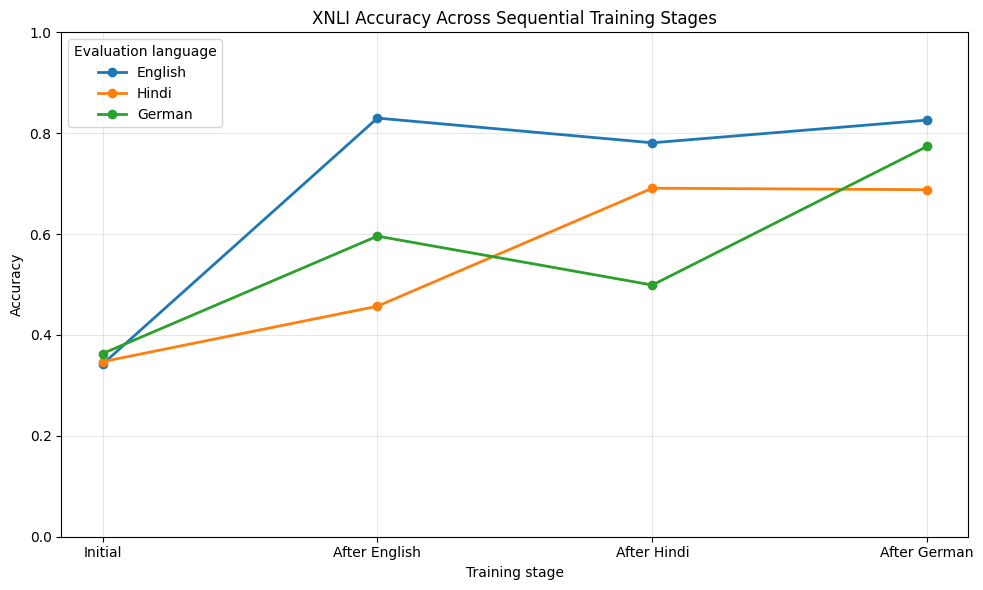

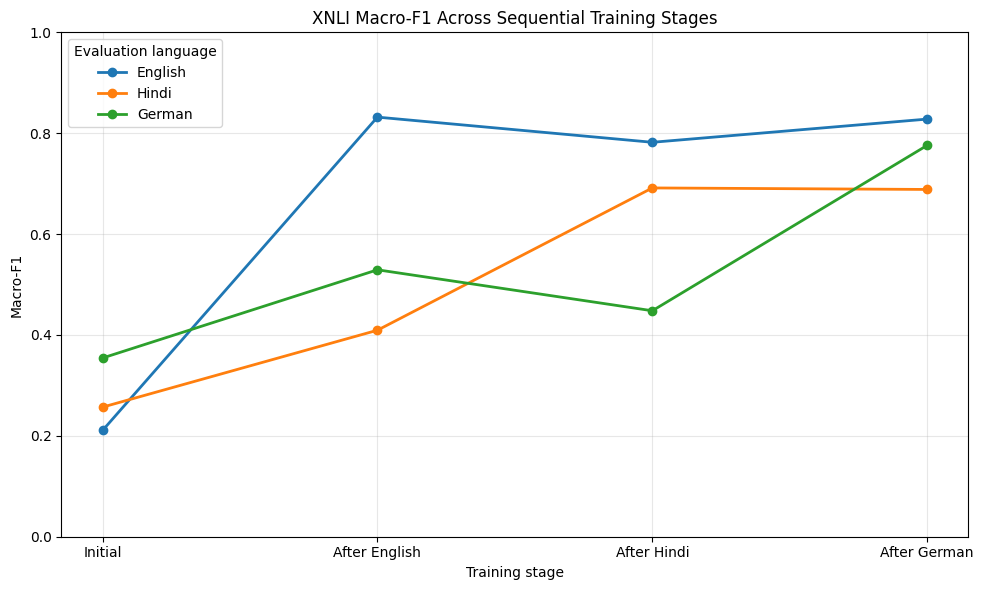

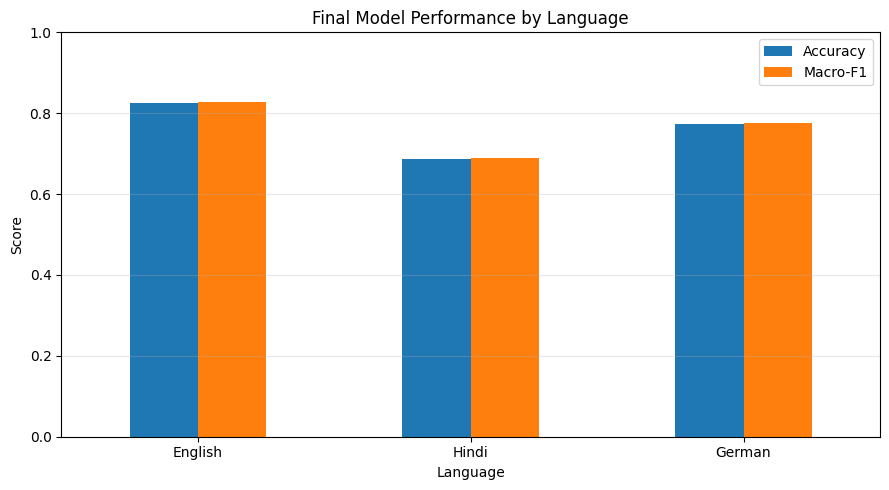

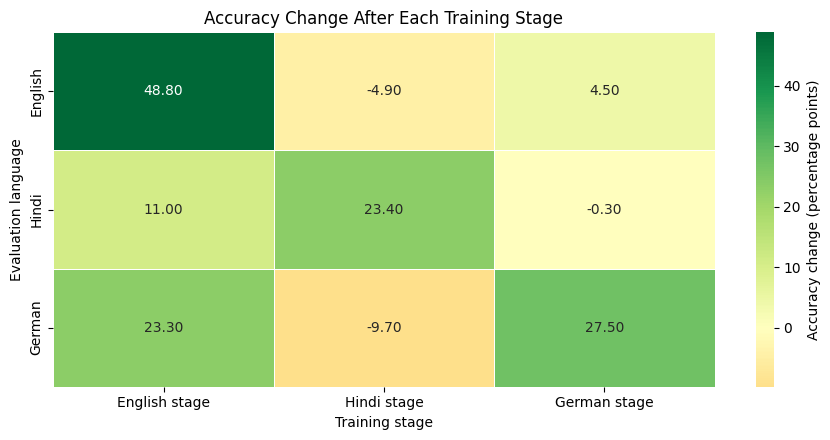

FINAL SUMMARY
Mean final accuracy: 0.7627
Mean final Macro-F1: 0.7642

Plot files saved in: /content/xnli_lora_baseline/results
Saved files:
- accuracy_across_stages.png
- accuracy_change_heatmap.png
- accuracy_matrix.csv
- baseline_results.json
- final_language_comparison.png
- macro_f1_across_stages.png
- macro_f1_matrix.csv


In [33]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# -----------------------------
# 1. Define the measured results
# -----------------------------

stages = ["Initial", "After English", "After Hindi", "After German"]
languages = ["English", "Hindi", "German"]

accuracy = pd.DataFrame(
    {
        "English": [0.3420, 0.8300, 0.7810, 0.8260],
        "Hindi":   [0.3470, 0.4570, 0.6910, 0.6880],
        "German":  [0.3630, 0.5960, 0.4990, 0.7740],
    },
    index=stages,
)

macro_f1 = pd.DataFrame(
    {
        "English": [0.2106, 0.8319, 0.7820, 0.8280],
        "Hindi":   [0.2569, 0.4094, 0.6915, 0.6885],
        "German":  [0.3543, 0.5292, 0.4480, 0.7760],
    },
    index=stages,
)

# Save the plotting data alongside experiment results.
RESULTS_DIR = "/content/xnli_lora_baseline/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

accuracy.to_csv(os.path.join(RESULTS_DIR, "accuracy_matrix.csv"))
macro_f1.to_csv(os.path.join(RESULTS_DIR, "macro_f1_matrix.csv"))

# -----------------------------
# 2. Display the performance matrix
# -----------------------------

print("ACCURACY MATRIX")
display((accuracy * 100).round(2).rename_axis("Training stage"))

print("MACRO-F1 MATRIX")
display(macro_f1.round(4).rename_axis("Training stage"))

# -----------------------------
# 3. Plot accuracy across stages
# -----------------------------

plt.figure(figsize=(10, 6))

for language in languages:
    plt.plot(
        stages,
        accuracy[language],
        marker="o",
        linewidth=2,
        label=language,
    )

plt.title("XNLI Accuracy Across Sequential Training Stages")
plt.xlabel("Training stage")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend(title="Evaluation language")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "accuracy_across_stages.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# -----------------------------
# 4. Plot Macro-F1 across stages
# -----------------------------

plt.figure(figsize=(10, 6))

for language in languages:
    plt.plot(
        stages,
        macro_f1[language],
        marker="o",
        linewidth=2,
        label=language,
    )

plt.title("XNLI Macro-F1 Across Sequential Training Stages")
plt.xlabel("Training stage")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend(title="Evaluation language")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "macro_f1_across_stages.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# -----------------------------
# 5. Compare final accuracy and Macro-F1
# -----------------------------

final_metrics = pd.DataFrame(
    {
        "Accuracy": accuracy.loc["After German"],
        "Macro-F1": macro_f1.loc["After German"],
    }
)

ax = final_metrics.plot(
    kind="bar",
    figsize=(9, 5),
)

ax.set_title("Final Model Performance by Language")
ax.set_xlabel("Language")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "final_language_comparison.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# -----------------------------
# 6. Accuracy-change heatmap
# -----------------------------

accuracy_changes = accuracy.diff().iloc[1:] * 100
accuracy_changes.index = [
    "English stage",
    "Hindi stage",
    "German stage",
]

plt.figure(figsize=(9, 4.5))

sns.heatmap(
    accuracy_changes.T,
    annot=True,
    fmt=".2f",
    center=0,
    cmap="RdYlGn",
    linewidths=0.5,
    cbar_kws={"label": "Accuracy change (percentage points)"},
)

plt.title("Accuracy Change After Each Training Stage")
plt.xlabel("Training stage")
plt.ylabel("Evaluation language")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "accuracy_change_heatmap.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# -----------------------------
# 7. Average final performance
# -----------------------------

print("FINAL SUMMARY")

print(
    "Mean final accuracy:",
    round(accuracy.loc["After German"].mean(), 4),
)

print(
    "Mean final Macro-F1:",
    round(macro_f1.loc["After German"].mean(), 4),
)

print("\nPlot files saved in:", RESULTS_DIR)
print("Saved files:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print("-", filename)

Accuracy Across Stages


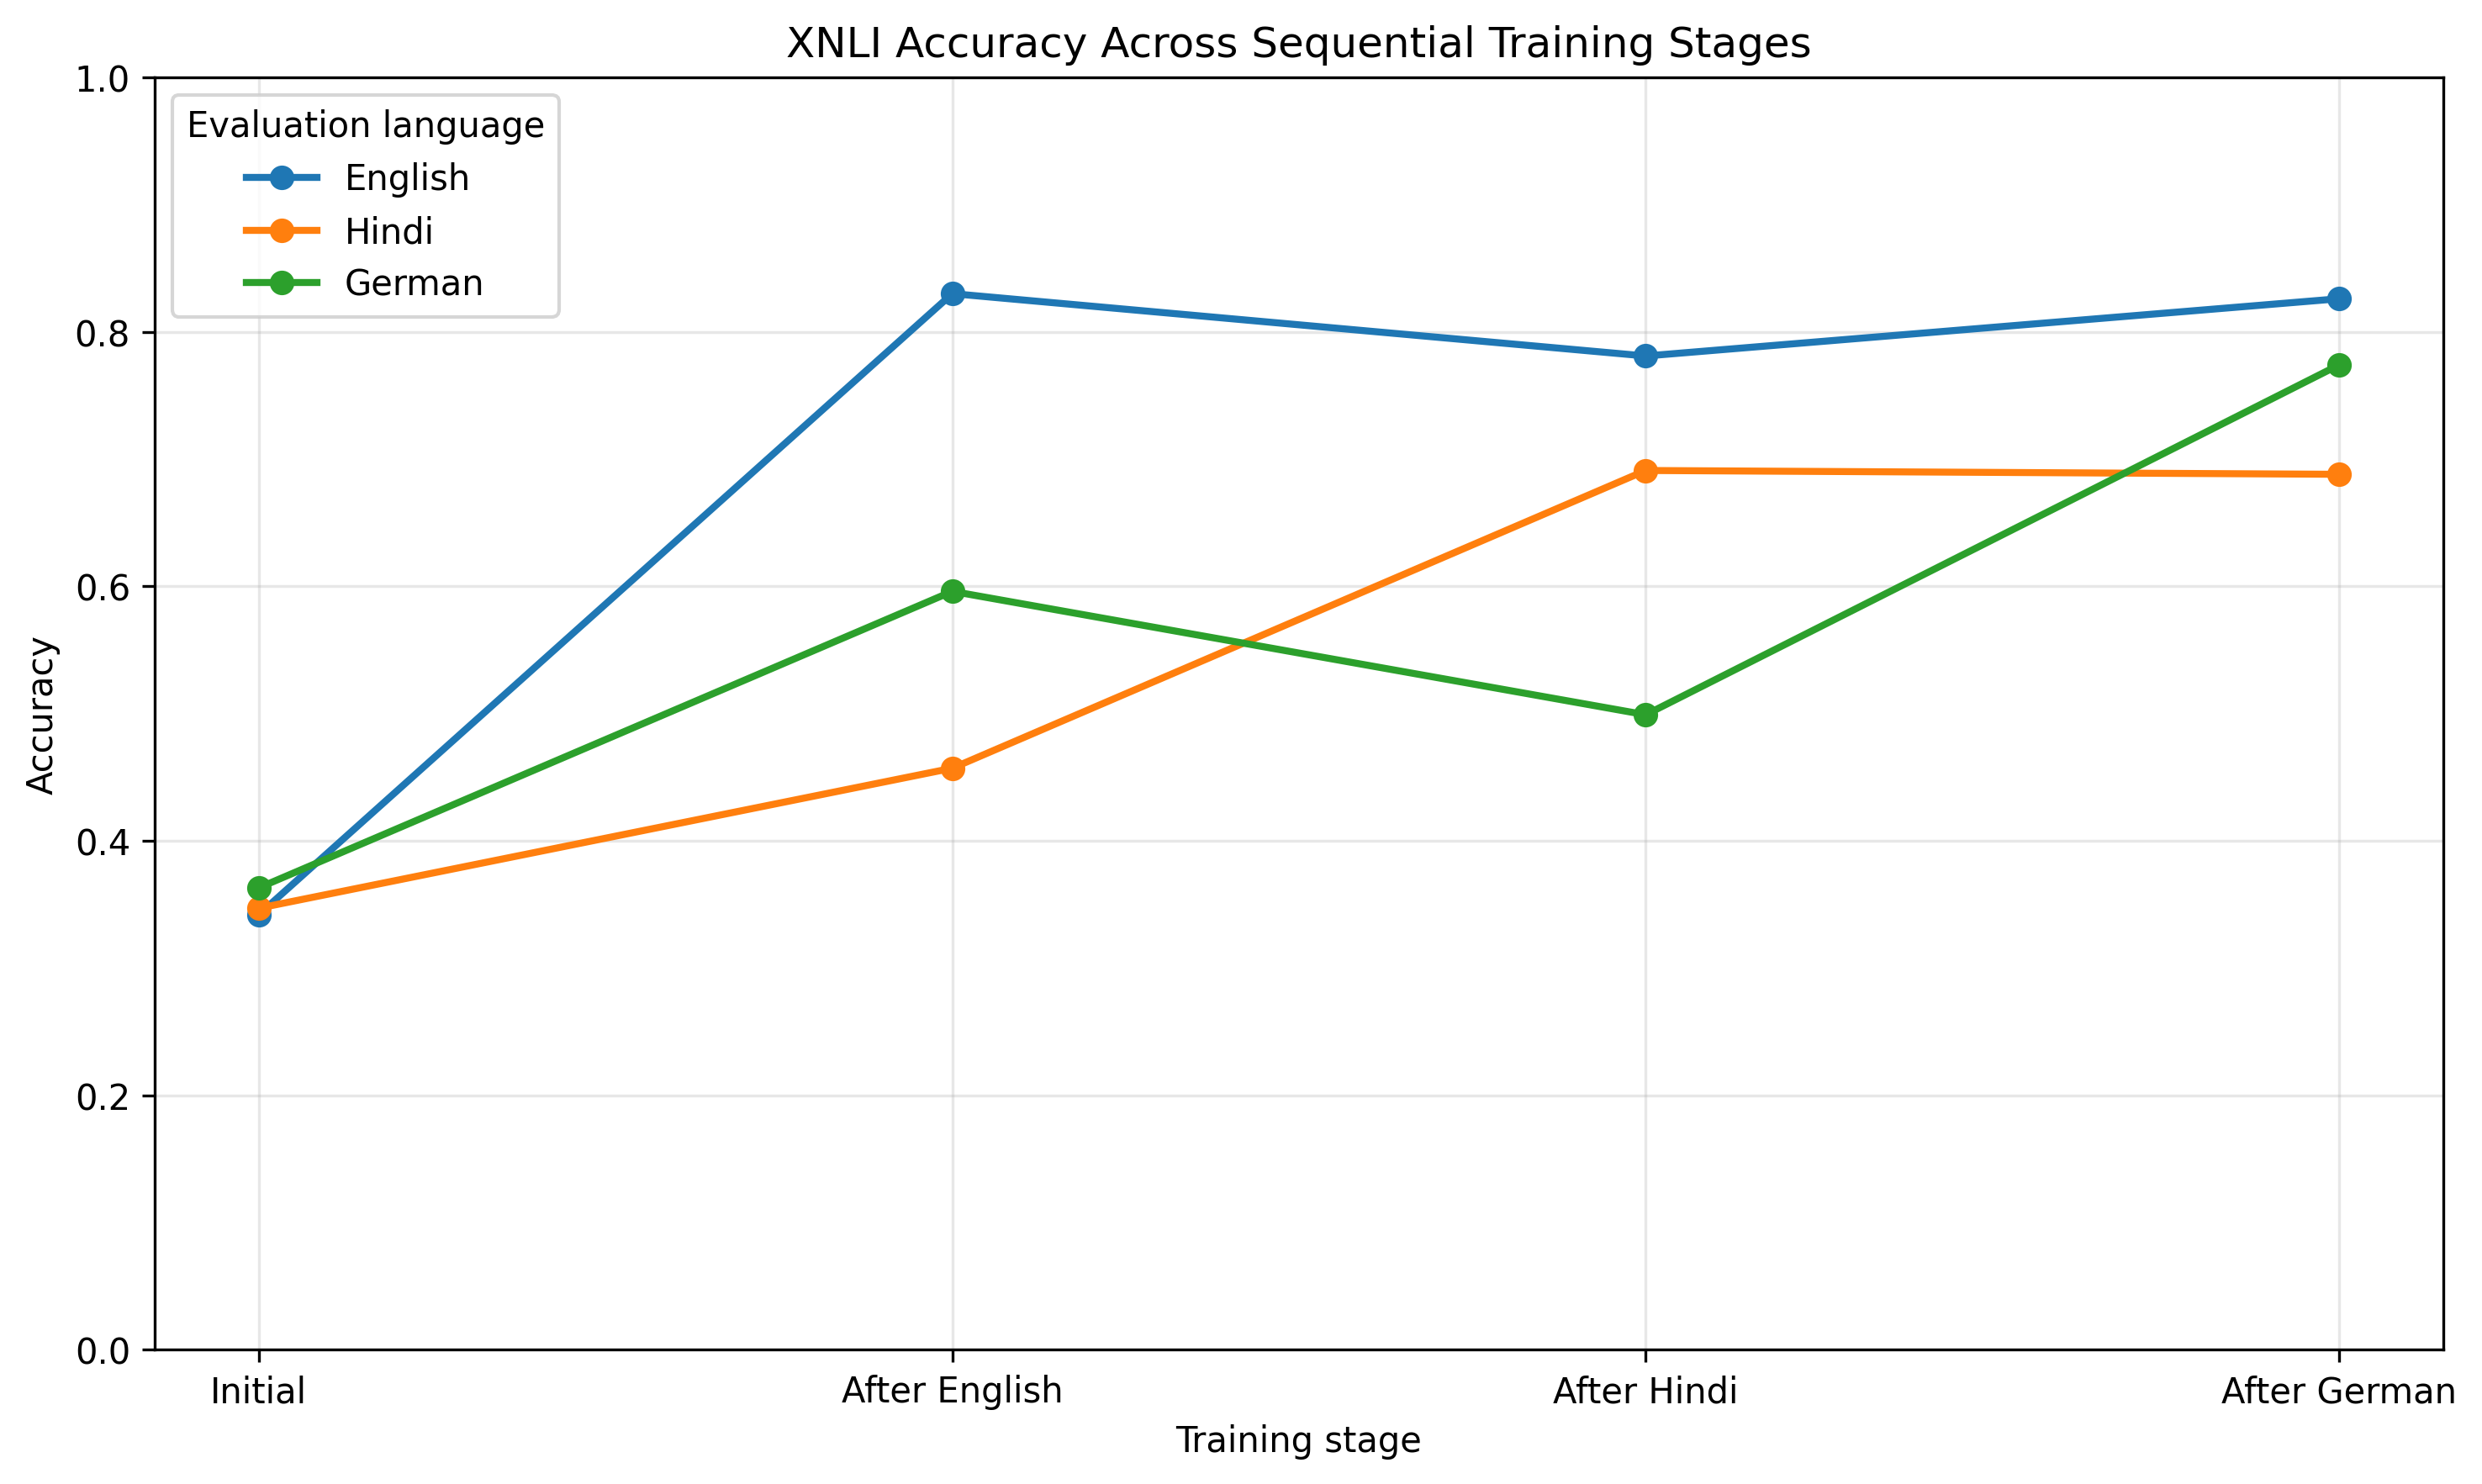

Macro F1 Across Stages


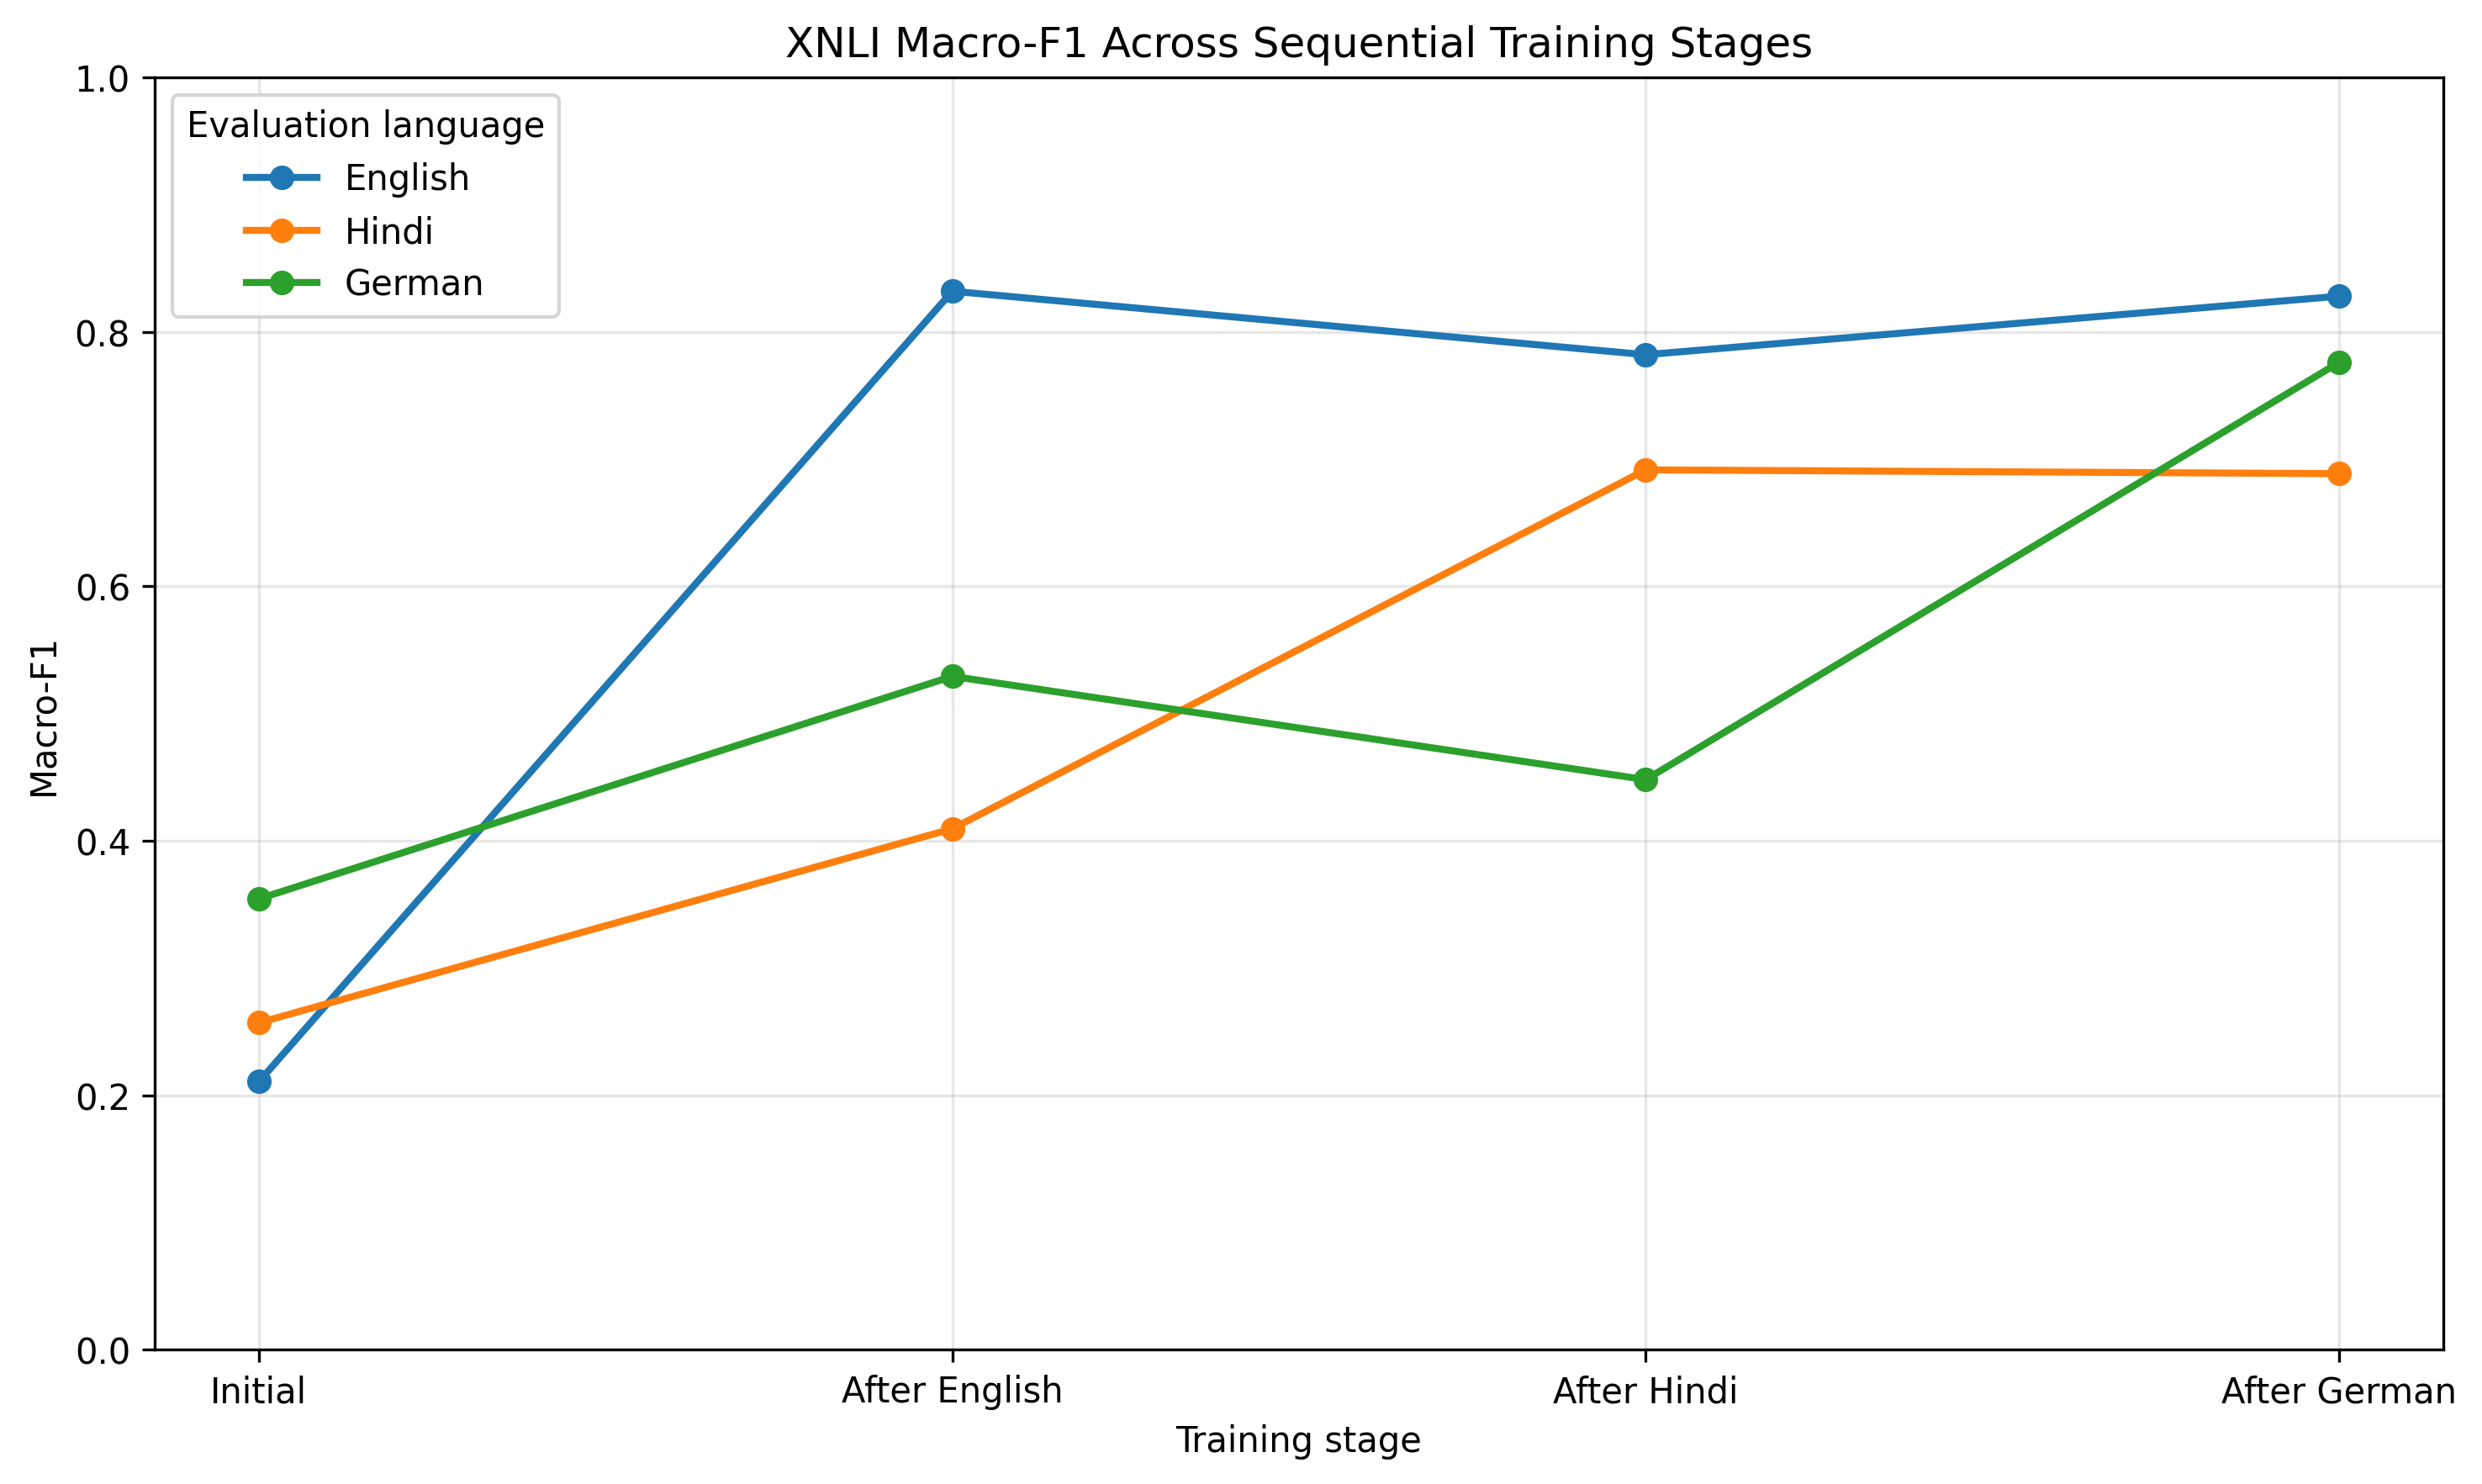

Final Language Comparison


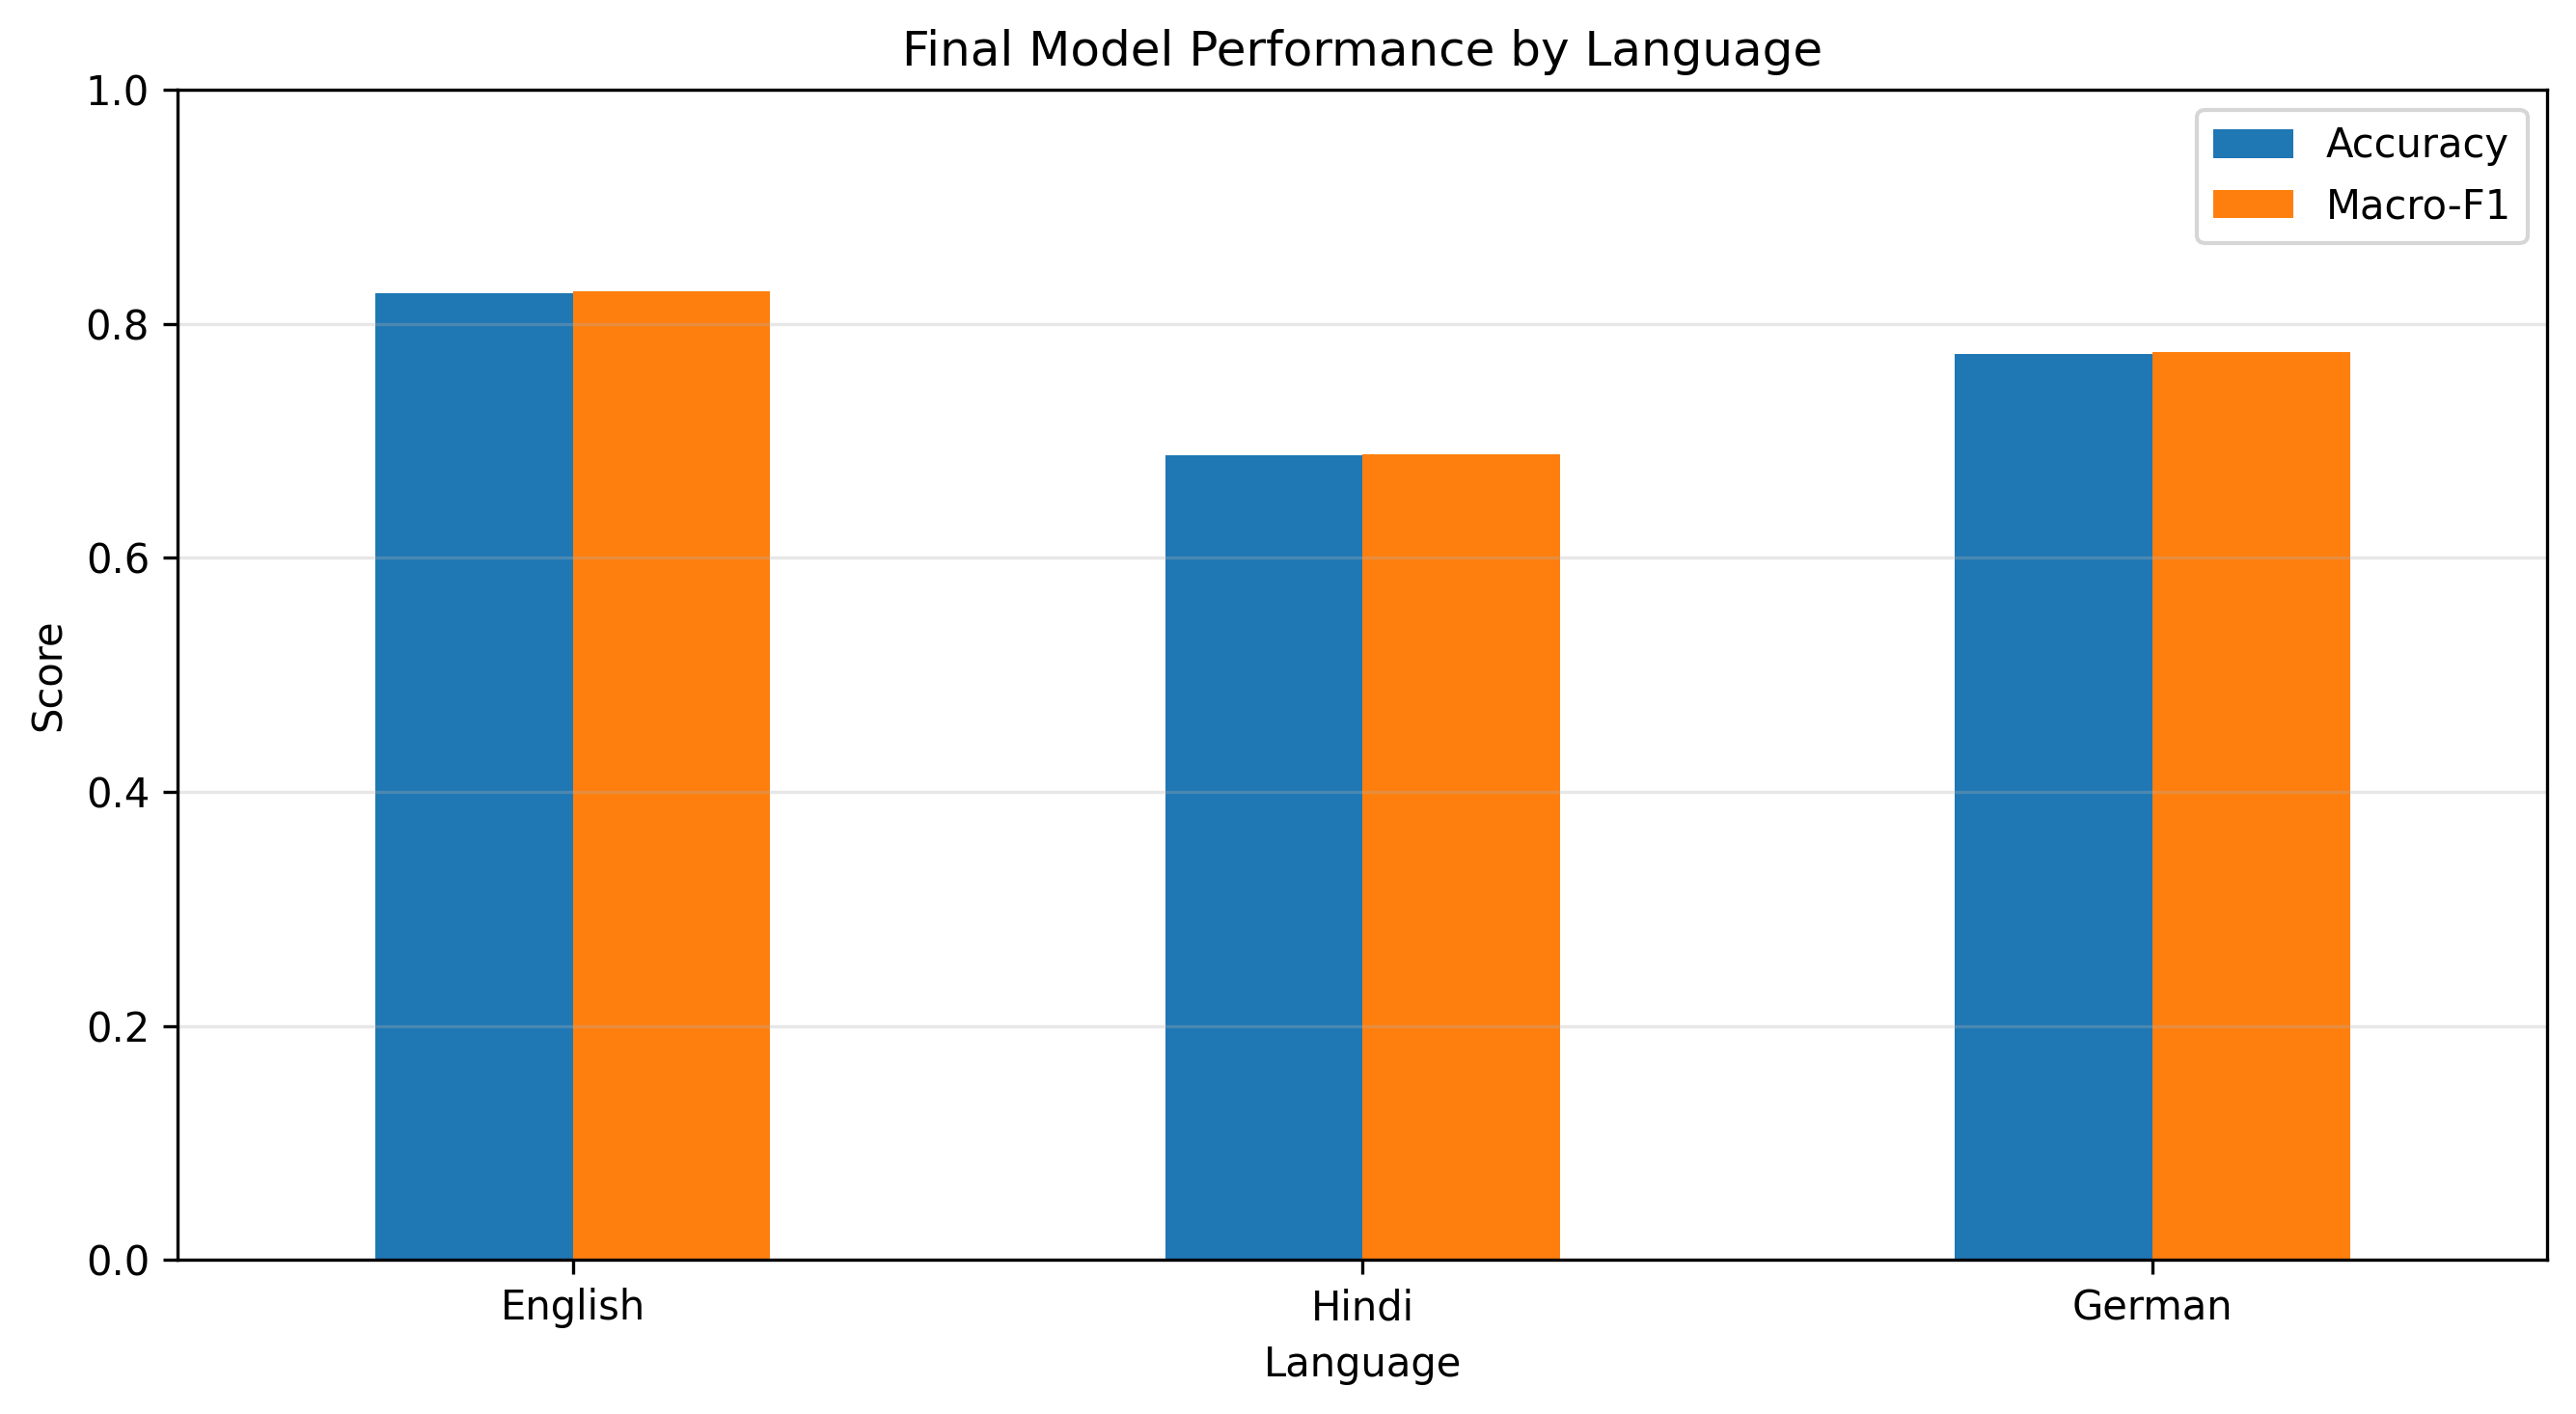

Accuracy Change Heatmap


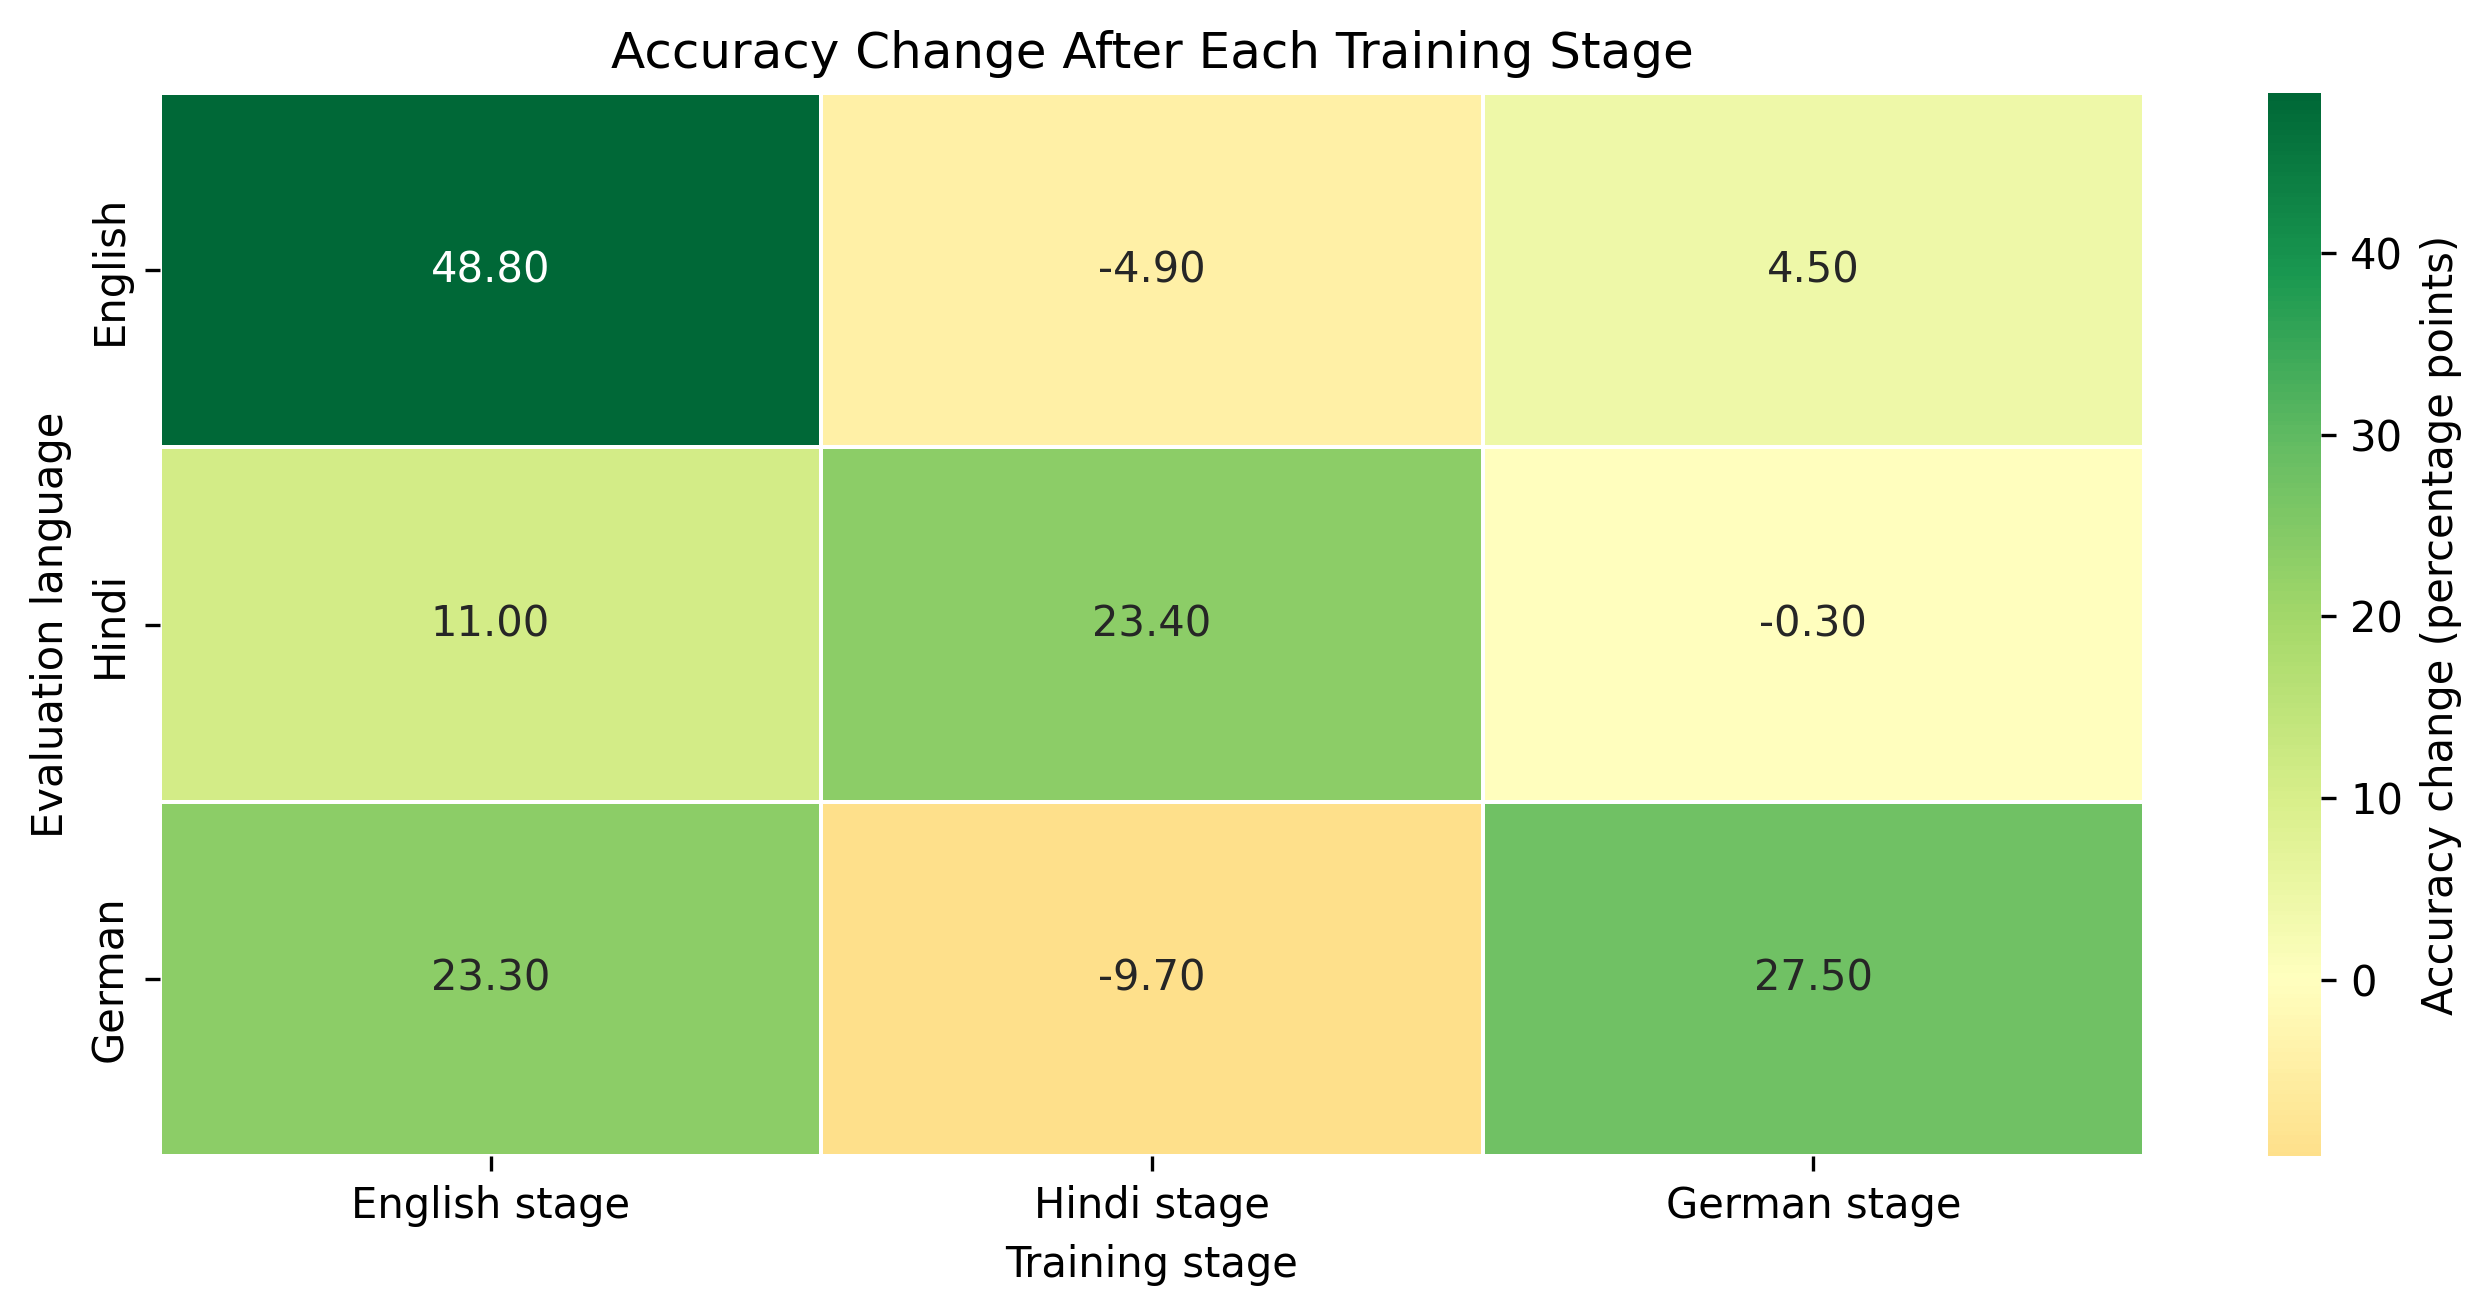

In [34]:
from IPython.display import display, Image
from pathlib import Path

results_dir = Path("/content/xnli_lora_baseline/results")

plot_files = [
    "accuracy_across_stages.png",
    "macro_f1_across_stages.png",
    "final_language_comparison.png",
    "accuracy_change_heatmap.png",
]

for filename in plot_files:
    filepath = results_dir / filename

    if filepath.exists():
        print(filename.replace("_", " ").replace(".png", "").title())
        display(Image(filename=str(filepath)))
    else:
        print(f"File not found: {filepath}")

In [35]:
from google.colab import drive
from pathlib import Path
import shutil
import json
import pandas as pd

# 1. Connect Google Drive
drive.mount("/content/drive")

# 2. Define source and destination folders
source_dir = Path("/content/xnli_lora_baseline/results")
drive_dir = Path(
    "/content/drive/MyDrive/Continual_Learning_Research/Phase1_Baseline_Results"
)

# 3. Create the destination folder
drive_dir.mkdir(parents=True, exist_ok=True)

# 4. Copy all results and plot files to Google Drive
if not source_dir.exists():
    raise FileNotFoundError(
        f"Results folder not found: {source_dir}"
    )

copied_files = []

for file_path in source_dir.iterdir():
    if file_path.is_file():
        shutil.copy2(file_path, drive_dir / file_path.name)
        copied_files.append(file_path.name)

# 5. Save a readable summary of the final results
summary = {
    "experiment": "XNLI LoRA Sequential Baseline Pilot",
    "language_order": ["English", "Hindi", "German"],
    "final_accuracy": {
        "English": 0.8260,
        "Hindi": 0.6880,
        "German": 0.7740
    },
    "final_macro_f1": {
        "English": 0.8280,
        "Hindi": 0.6885,
        "German": 0.7760
    },
    "mean_final_accuracy": 0.7627,
    "mean_final_macro_f1": 0.7642
}

summary_path = drive_dir / "final_results_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

# 6. Confirm saved files
print("Results saved to Google Drive:")
print(drive_dir)
print()

for filename in sorted(copied_files):
    print("✓", filename)

print("✓", summary_path.name)

Mounted at /content/drive
Results saved to Google Drive:
/content/drive/MyDrive/Continual_Learning_Research/Phase1_Baseline_Results

✓ accuracy_across_stages.png
✓ accuracy_change_heatmap.png
✓ accuracy_matrix.csv
✓ baseline_results.json
✓ final_language_comparison.png
✓ macro_f1_across_stages.png
✓ macro_f1_matrix.csv
✓ final_results_summary.json


In [36]:
from pathlib import Path
import shutil

source_model = Path("/content/xnli_lora_baseline/final_model")

drive_model = Path(
    "/content/drive/MyDrive/Continual_Learning_Research/"
    "Phase1_Baseline_Results/final_model"
)

if not source_model.exists():
    raise FileNotFoundError(
        f"Trained model not found: {source_model}"
    )

shutil.copytree(
    source_model,
    drive_model,
    dirs_exist_ok=True
)

print("Model backup completed.")
print("Saved to:", drive_model)

print("\nSaved model files:")
for file_path in sorted(drive_model.rglob("*")):
    if file_path.is_file():
        print(f"{file_path.relative_to(drive_model)} "
              f"({file_path.stat().st_size / (1024**2):.2f} MB)")

Model backup completed.
Saved to: /content/drive/MyDrive/Continual_Learning_Research/Phase1_Baseline_Results/final_model

Saved model files:
README.md (0.00 MB)
adapter_config.json (0.00 MB)
adapter_model.safetensors (13.04 MB)
tokenizer.json (16.41 MB)
tokenizer_config.json (0.00 MB)
